<a href="https://colab.research.google.com/github/Swetha0407/ITA0305/blob/main/Exp2-Erlang_B_Traffic_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

N    Q    ch/cell  S/I(dB)
3     3.00   112.0   11.30
4     3.46    84.0   13.80
7     4.58    48.0   18.66
9     5.20    37.3   20.85
12    6.00    28.0   23.34


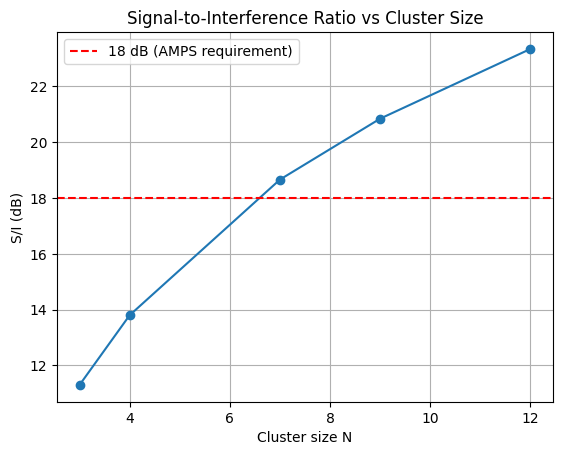

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Erlang B formula
def erlang_b(A, N):
    numerator = (A ** N) / math.factorial(N)

    denominator = 0
    for k in range(N + 1):
        denominator += (A ** k) / math.factorial(k)

    return numerator / denominator


# Traffic load range
traffic = np.arange(1, 31, 1)

# Number of available channels
channels = [5, 10, 15, 20]

# Calculate blocking probability
plt.figure(figsize=(9, 5))

for N in channels:
    blocking = []

    for A in traffic:
        blocking.append(erlang_b(A, N) * 100)

    plt.plot(traffic, blocking, marker='o',
             label=str(N) + " Channels")

# Graph formatting
plt.title("Erlang B - Call Blocking Probability")
plt.xlabel("Offered Traffic (Erlangs)")
plt.ylabel("Blocking Probability (%)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# Display sample results
print("ERLANG B RESULTS")
print("----------------")

for N in channels:
    probability = erlang_b(10, N) * 100
    print("Channels:", N,
          "| Traffic: 10 Erlangs",
          "| Blocking:", round(probability, 4), "%")
